In [1]:
from pathlib import Path
import json
import math

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader, Subset

from data_handle.embed import DatasetConfig, get_embed
from models.autoencoder import vae_models
from utils import preprocess_imgs_vae

torch.set_grad_enabled(False)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
print("torch:", torch.__version__)

/vol/biomedic3/tx1215/REPA-E/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cuda
torch: 2.3.1+cu121


In [2]:
DATA_DIR = "/vol/biodata/data/Mammo/EMBED/pngs/1024x768"
SPLIT_DIR = "/vol/biomedic3/tx1215/mamo-flow/assets/embed_splits_v1"
HEIGHT = 256
WIDTH = 192
VAE_NAME = "f8d4"
VAE_CKPT = "pretrained/sdvae-f8d4/sdvae-f8d4.pt"

INDEX = 0
BATCH_SIZE = 16
SCAN_N = 1000


DATA_DIR = Path(DATA_DIR)
SPLIT_DIR = Path(SPLIT_DIR)
VAE_CKPT = Path(VAE_CKPT)

print("DATA_DIR :", DATA_DIR)
print("SPLIT_DIR:", SPLIT_DIR)
print("resolution:", HEIGHT, "x", WIDTH)
print("VAE_NAME  :", VAE_NAME)
print("VAE_CKPT  :", VAE_CKPT)

DATA_DIR : /vol/biodata/data/Mammo/EMBED/pngs/1024x768
SPLIT_DIR: /vol/biomedic3/tx1215/mamo-flow/assets/embed_splits_v1
resolution: 256 x 192
VAE_NAME  : f8d4
VAE_CKPT  : pretrained/sdvae-f8d4/sdvae-f8d4.pt


In [3]:
def describe_tensor(name, x):
    x = x.detach().float().cpu()
    flat = x.flatten()
    finite = torch.isfinite(flat)
    finite_x = flat[finite]

    print(f"\n{name}")
    print(" shape :", tuple(x.shape))
    print(" dtype :", x.dtype)
    print(" finite:", f"{finite.sum().item()}/{flat.numel()}")

    if finite_x.numel() == 0:
        return

    qs = torch.quantile(
        finite_x,
        torch.tensor([0.0, 0.001, 0.01, 0.5, 0.99, 0.999, 1.0]),
    )

    print(" min/max:", float(finite_x.min()), float(finite_x.max()))
    print(" mean/std:", float(finite_x.mean()), float(finite_x.std(unbiased=False)))
    print(
        " quantiles [0,.001,.01,.5,.99,.999,1]:",
        [round(float(v), 6) for v in qs],
    )


def describe_channels(name, x):
    x = x.detach().float().cpu()
    if x.ndim != 4:
        raise ValueError(f"Expected BCHW, got {tuple(x.shape)}")

    print(f"\n{name} per-channel statistics")
    for c in range(x.shape[1]):
        v = x[:, c].flatten()
        print(
            f" c{c}: mean={v.mean(): .6f}, "
            f"std={v.std(unbiased=False): .6f}, "
            f"min={v.min(): .6f}, max={v.max(): .6f}, "
            f"absmax={v.abs().max(): .6f}"
        )


def show_gray(title, x):
    x = x.detach().float().cpu()
    if x.ndim == 3:
        x = x.mean(dim=0)
    plt.figure(figsize=(7, 5))
    plt.imshow(x, cmap="gray")
    plt.title(title)
    plt.axis("off")
    plt.show()

In [4]:
dataset_cfg = DatasetConfig(
    data_dir=str(DATA_DIR),
    split_dir=str(SPLIT_DIR),
    cache_dir=None,
    parents=["age", "view", "density", "scanner"],
    img_height=HEIGHT,
    img_width=WIDTH,
    img_channels=1,
)

datasets = get_embed(dataset_cfg)
train_ds = datasets["train"]

print("train size:", len(train_ds))

sample = train_ds[INDEX]
print("sample keys:", sample.keys())

for k, v in sample.items():
    if torch.is_tensor(v):
        print(k, tuple(v.shape), v.dtype)
    elif isinstance(v, dict):
        print(k, {kk: (tuple(vv.shape), vv.dtype) for kk, vv in v.items()})
    else:
        print(k, type(v), v)

train size: 237746
sample keys: dict_keys(['x', 'pa', 'shortpath', 'cache_idx'])
x (1, 256, 192) torch.float32
pa {'age': ((1,), torch.float32), 'view': ((2,), torch.float32), 'density': ((4,), torch.float32), 'scanner': ((5,), torch.float32)}
shortpath <class 'str'> cohort_1/60696029/1.2.845.113979.3.66.1.48576351.20131116.1100119/1.2.849.113688.2750825174.1384237796.3781.1309/1.2.826.0.1.3680043.8.498.57863081415434463223208365979079263200.png
cache_idx () torch.int64



dataset x
 shape : (1, 256, 192)
 dtype : torch.float32
 finite: 49152/49152
 min/max: 0.0 0.9999923706054688
 mean/std: 0.08804208040237427 0.15187935531139374
 quantiles [0,.001,.01,.5,.99,.999,1]: [0.0, 0.0, 0.0, 0.0, 0.611281, 0.858391, 0.999992]


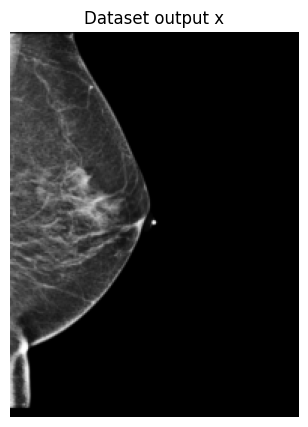


Expected for current training:
  shape ≈ (1, H, W)
  range ≈ [0, 1]


In [5]:
x = sample["x"]

describe_tensor("dataset x", x)
show_gray("Dataset output x", x)

print("\nExpected for current training:")
print("  shape ≈ (1, H, W)")
print("  range ≈ [0, 1]")


raw_image passed toward VAE preprocessing
 shape : (1, 3, 256, 192)
 dtype : torch.float32
 finite: 147456/147456
 min/max: 0.0 254.998046875
 mean/std: 22.45073127746582 38.7292366027832
 quantiles [0,.001,.01,.5,.99,.999,1]: [0.0, 0.0, 0.0, 0.0, 155.894531, 218.945328, 254.998047]

raw_image per-channel statistics
 c0: mean= 22.450729, std= 38.729237, min= 0.000000, max= 254.998047, absmax= 254.998047
 c1: mean= 22.450729, std= 38.729237, min= 0.000000, max= 254.998047, absmax= 254.998047
 c2: mean= 22.450729, std= 38.729237, min= 0.000000, max= 254.998047, absmax= 254.998047


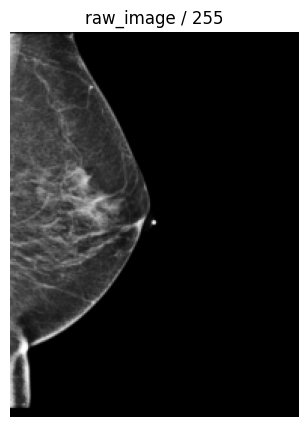


Expected:
  shape: (1, 3, H, W)
  range: [0, 255]


In [7]:
x_batch = x.unsqueeze(0).to(device)

raw_image = x_batch.repeat(1, 3, 1, 1) * 255.0

describe_tensor("raw_image passed toward VAE preprocessing", raw_image)
describe_channels("raw_image", raw_image)

show_gray("raw_image / 255", raw_image[0] / 255.0)

print("\nExpected:")
print("  shape: (1, 3, H, W)")
print("  range: [0, 255]")

In [8]:
raw_image.float() / 127.5 - 1

tensor([[[[-0.6392, -0.6553, -0.6659,  ..., -1.0000, -1.0000, -1.0000],
          [ 0.5180,  0.4739,  0.3970,  ..., -1.0000, -1.0000, -1.0000],
          [ 0.6343,  0.5162,  0.1595,  ..., -1.0000, -1.0000, -1.0000],
          ...,
          [-1.0000, -1.0000, -1.0000,  ..., -1.0000, -1.0000, -1.0000],
          [-1.0000, -1.0000, -1.0000,  ..., -1.0000, -1.0000, -1.0000],
          [-1.0000, -1.0000, -1.0000,  ..., -1.0000, -1.0000, -1.0000]],

         [[-0.6392, -0.6553, -0.6659,  ..., -1.0000, -1.0000, -1.0000],
          [ 0.5180,  0.4739,  0.3970,  ..., -1.0000, -1.0000, -1.0000],
          [ 0.6343,  0.5162,  0.1595,  ..., -1.0000, -1.0000, -1.0000],
          ...,
          [-1.0000, -1.0000, -1.0000,  ..., -1.0000, -1.0000, -1.0000],
          [-1.0000, -1.0000, -1.0000,  ..., -1.0000, -1.0000, -1.0000],
          [-1.0000, -1.0000, -1.0000,  ..., -1.0000, -1.0000, -1.0000]],

         [[-0.6392, -0.6553, -0.6659,  ..., -1.0000, -1.0000, -1.0000],
          [ 0.5180,  0.4739,  


VAE input after preprocess_imgs_vae
 shape : (1, 3, 256, 192)
 dtype : torch.float32
 finite: 147456/147456
 min/max: -1.0 0.9999847412109375
 mean/std: -0.8239157795906067 0.30375874042510986
 quantiles [0,.001,.01,.5,.99,.999,1]: [-1.0, -1.0, -1.0, -1.0, 0.222702, 0.717218, 0.999985]

VAE input per-channel statistics
 c0: mean=-0.823916, std= 0.303759, min=-1.000000, max= 0.999985, absmax= 1.000000
 c1: mean=-0.823916, std= 0.303759, min=-1.000000, max= 0.999985, absmax= 1.000000
 c2: mean=-0.823916, std= 0.303759, min=-1.000000, max= 0.999985, absmax= 1.000000

max |preprocess_imgs_vae(x) - (x/127.5-1)| = 0.0


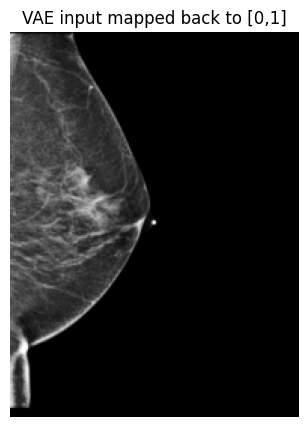


Expected:
  range ≈ [-1, 1]


In [9]:
vae_input = preprocess_imgs_vae(raw_image)
expected_vae_input = raw_image.float() / 127.5 - 1.0

describe_tensor("VAE input after preprocess_imgs_vae", vae_input)
describe_channels("VAE input", vae_input)

print(
    "\nmax |preprocess_imgs_vae(x) - (x/127.5-1)| =",
    float((vae_input.float() - expected_vae_input.float()).abs().max().cpu()),
)

show_gray("VAE input mapped back to [0,1]", (vae_input[0] + 1.0) / 2.0)

print("\nExpected:")
print("  range ≈ [-1, 1]")

In [10]:
vae = vae_models[VAE_NAME]().to(device)

state = torch.load(VAE_CKPT, map_location=device)
missing, unexpected = vae.load_state_dict(state, strict=False)

print("missing keys   :", missing)
print("unexpected keys:", unexpected)

del state

vae.eval()
vae.float()
for p in vae.parameters():
    p.requires_grad_(False)

print("VAE loaded")

missing keys   : []
unexpected keys: []
VAE loaded


In [11]:
posterior, z, reconstruction = vae(vae_input.float())

In [12]:
with torch.autocast(device_type=device.type, enabled=False):
    posterior, z, reconstruction = vae(vae_input.float())

describe_tensor("sampled latent z", z)
describe_channels("sampled latent z", z)

print("\nposterior type:", type(posterior))

posterior_mean = getattr(posterior, "mean", None)
posterior_std = getattr(posterior, "std", None)

if torch.is_tensor(posterior_mean):
    describe_tensor("posterior.mean", posterior_mean)
    describe_channels("posterior.mean", posterior_mean)

if torch.is_tensor(posterior_std):
    describe_tensor("posterior.std", posterior_std)
    describe_channels("posterior.std", posterior_std)

if reconstruction is not None:
    describe_tensor("VAE reconstruction raw output", reconstruction)


sampled latent z
 shape : (1, 4, 32, 24)
 dtype : torch.float32
 finite: 3072/3072
 min/max: -18.635377883911133 20.089963912963867
 mean/std: -1.414623737335205 7.776828289031982
 quantiles [0,.001,.01,.5,.99,.999,1]: [-18.635378, -17.083429, -14.68698, -0.690858, 7.853764, 11.421589, 20.089964]

sampled latent z per-channel statistics
 c0: mean=-4.664148, std= 3.159768, min=-12.652030, max= 20.089964, absmax= 20.089964
 c1: mean=-10.751930, std= 5.779378, min=-18.635378, max= 10.775512, absmax= 18.635378
 c2: mean= 4.655529, std= 3.075351, min=-12.160118, max= 8.963263, absmax= 12.160118
 c3: mean= 5.102055, std= 3.466202, min=-7.130762, max= 13.658784, absmax= 13.658784

posterior type: <class 'models.autoencoder.DiagonalGaussianDistribution'>

posterior.mean
 shape : (1, 4, 32, 24)
 dtype : torch.float32
 finite: 3072/3072
 min/max: -18.6353702545166 20.0899658203125
 mean/std: -1.4146132469177246 7.776833534240723
 quantiles [0,.001,.01,.5,.99,.999,1]: [-18.63537, -17.083441, -14

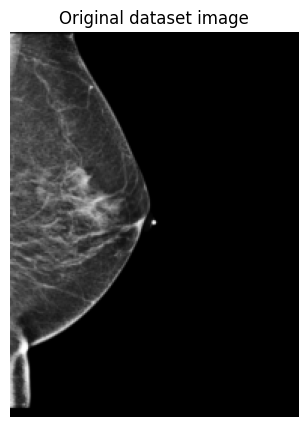

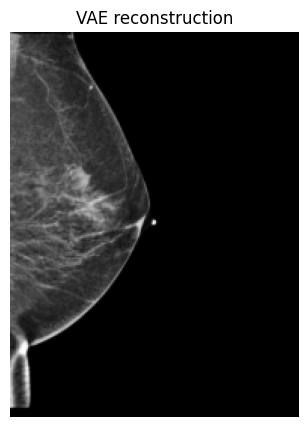

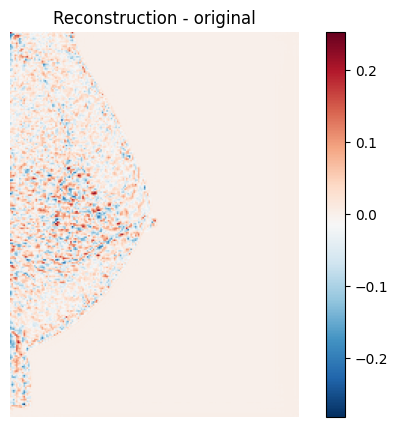

In [13]:
if reconstruction is not None:
    recon_01 = ((reconstruction[0].detach().float().cpu() + 1.0) / 2.0).clamp(0, 1)
    original_01 = x.detach().float().cpu().clamp(0, 1)

    show_gray("Original dataset image", original_01)
    show_gray("VAE reconstruction", recon_01)

    diff = recon_01.mean(dim=0) - original_01.mean(dim=0)
    plt.figure(figsize=(7, 5))
    plt.imshow(diff, cmap="RdBu_r")
    plt.title("Reconstruction - original")
    plt.axis("off")
    plt.colorbar()
    plt.show()

In [14]:
stats_path = VAE_CKPT.parent / f"embed_{VAE_NAME}_{HEIGHT}x{WIDTH}_latent_stats.pt"
print("stats path:", stats_path)

stats = torch.load(stats_path, map_location="cpu")
print("keys:", stats.keys())

latent_mean = stats["mean"].squeeze().float()
latent_std = stats["std"].squeeze().float()

print("\nstored latent mean:", latent_mean)
print("stored latent std :", latent_std)
print("stored scale=1/std:", latent_std.reciprocal())

assert torch.isfinite(latent_mean).all()
assert torch.isfinite(latent_std).all()
assert (latent_std > 0).all()

stats path: pretrained/sdvae-f8d4/embed_f8d4_256x192_latent_stats.pt
keys: dict_keys(['mean', 'std'])

stored latent mean: tensor([ -4.3434, -10.2545,   4.4211,   4.7741])
stored latent std : tensor([3.4168, 6.0689, 3.2001, 3.6828])
stored scale=1/std: tensor([0.2927, 0.1648, 0.3125, 0.2715])


In [15]:
C = z.shape[1]

bn = torch.nn.BatchNorm2d(
    C,
    eps=1e-4,
    momentum=0.1,
    affine=False,
    track_running_stats=True,
).to(device)

bn.running_mean.copy_(latent_mean.to(device))
bn.running_var.copy_(latent_std.pow(2).to(device))
bn.eval()

z_norm = bn(z.float())

mean4 = latent_mean.to(device).view(1, C, 1, 1)
std4 = latent_std.to(device).view(1, C, 1, 1)

z_norm_manual = (z.float() - mean4) / torch.sqrt(std4.pow(2) + bn.eps)

print("max |BN - manual|:", float((z_norm - z_norm_manual).abs().max().cpu()))

describe_tensor("normalized latent", z_norm)
describe_channels("normalized latent", z_norm)

max |BN - manual|: 4.76837158203125e-07

normalized latent
 shape : (1, 4, 32, 24)
 dtype : torch.float32
 finite: 3072/3072
 min/max: -5.181447982788086 7.150853157043457
 mean/std: -0.0033795125782489777 0.9487107396125793
 quantiles [0,.001,.01,.5,.99,.999,1]: [-5.181448, -3.222974, -2.259873, -0.252138, 2.446521, 3.531503, 7.150853]

normalized latent per-channel statistics
 c0: mean=-0.093866, std= 0.924761, min=-2.431658, max= 7.150853, absmax= 7.150853
 c1: mean=-0.081972, std= 0.952297, min=-1.380967, max= 3.465212, absmax= 3.465212
 c2: mean= 0.073260, std= 0.961014, min=-5.181448, max= 1.419380, absmax= 5.181448
 c3: mean= 0.089060, std= 0.941183, min=-3.232536, max= 2.412482, absmax= 3.232536


In [17]:
loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False,
)

batch = next(iter(loader))

batch_x = batch["x"].to(device)
batch_raw = batch_x.repeat(1, 3, 1, 1) * 255.0
batch_vae_input = preprocess_imgs_vae(batch_raw)

with torch.no_grad(), torch.autocast(device_type=device.type, enabled=False):
    batch_posterior, batch_z, _ = vae(batch_vae_input.float())

batch_z_norm = bn(batch_z.float())

describe_tensor("batch dataset x", batch_x)
describe_tensor("batch VAE input", batch_vae_input)
describe_channels("batch raw latent", batch_z)
describe_channels("batch normalized latent", batch_z_norm)


batch dataset x
 shape : (16, 1, 256, 192)
 dtype : torch.float32
 finite: 786432/786432
 min/max: 0.0 1.0
 mean/std: 0.09813738614320755 0.16721802949905396
 quantiles [0,.001,.01,.5,.99,.999,1]: [0.0, 0.0, 0.0, 0.0, 0.701038, 0.872408, 1.0]

batch VAE input
 shape : (16, 3, 256, 192)
 dtype : torch.float32
 finite: 2359296/2359296
 min/max: -1.0 1.0
 mean/std: -0.8037252426147461 0.3344360888004303
 quantiles [0,.001,.01,.5,.99,.999,1]: [-1.0, -1.0, -1.0, -1.0, 0.402084, 0.745054, 1.0]

batch raw latent per-channel statistics
 c0: mean=-4.537371, std= 3.226968, min=-14.324146, max= 20.089241, absmax= 20.089241
 c1: mean=-10.204468, std= 5.977067, min=-18.635075, max= 17.976187, absmax= 18.635075
 c2: mean= 4.343324, std= 3.276768, min=-19.920839, max= 10.328259, absmax= 19.920839
 c3: mean= 4.753749, std= 3.631149, min=-8.320843, max= 13.849016, absmax= 13.849016

batch normalized latent per-channel statistics
 c0: mean=-0.056762, std= 0.944428, min=-2.921032, max= 7.150641, absmax=

In [18]:
emp_mean = batch_z.float().mean(dim=(0, 2, 3)).cpu()
emp_std = batch_z.float().std(dim=(0, 2, 3), unbiased=False).cpu()

print("channel | empirical mean | stored mean | difference | empirical std | stored std | std ratio")

for c in range(batch_z.shape[1]):
    print(
        f"{c:7d} | "
        f"{emp_mean[c]:14.6f} | "
        f"{latent_mean[c]:11.6f} | "
        f"{(emp_mean[c] - latent_mean[c]):10.6f} | "
        f"{emp_std[c]:13.6f} | "
        f"{latent_std[c]:10.6f} | "
        f"{(emp_std[c] / latent_std[c]):9.4f}"
    )

channel | empirical mean | stored mean | difference | empirical std | stored std | std ratio
      0 |      -4.537371 |   -4.343422 |  -0.193948 |      3.226968 |   3.416835 |    0.9444
      1 |     -10.204468 |  -10.254453 |   0.049985 |      5.977067 |   6.068874 |    0.9849
      2 |       4.343324 |    4.421090 |  -0.077765 |      3.276768 |   3.200095 |    1.0240
      3 |       4.753749 |    4.774064 |  -0.020314 |      3.631149 |   3.682799 |    0.9860


In [20]:
from tqdm.auto import tqdm
SCAN_N = 5000

g = torch.Generator().manual_seed(0)
indices = torch.randperm(len(train_ds), generator=g)[:SCAN_N].tolist()

scan_ds = Subset(train_ds, indices)
scan_loader = DataLoader(
    scan_ds,
    batch_size=16,
    shuffle=False,
    num_workers=4,
    pin_memory=True,
)

all_z = []
all_z_norm = []
outliers = []

offset = 0

for batch in tqdm(scan_loader):
    bx = batch["x"].to(device, non_blocking=True)
    raw = bx.repeat(1, 3, 1, 1) * 255.0
    vae_input = preprocess_imgs_vae(raw)

    with torch.no_grad(), torch.autocast(device_type=device.type, enabled=False):
        _, z, _ = vae(vae_input.float())

    z_norm = bn(z.float())

    if not torch.isfinite(z).all():
        raise RuntimeError("Non-finite raw latent")
    if not torch.isfinite(z_norm).all():
        raise RuntimeError("Non-finite normalized latent")

    all_z.append(z.cpu())
    all_z_norm.append(z_norm.cpu())

    absmax = z_norm.abs().flatten(1).amax(1).cpu()

    for j in range(len(absmax)):
        outliers.append({
            "dataset_idx": indices[offset + j],
            "absmax": absmax[j].item(),
        })

    offset += len(absmax)

all_z = torch.cat(all_z)
all_z_norm = torch.cat(all_z_norm)

print("RAW")
describe_channels("raw latent", all_z)

print("\nNORMALIZED")
describe_channels("normalized latent", all_z_norm)

outliers = sorted(outliers, key=lambda x: x["absmax"], reverse=True)

print("\nTop 20:")
for x in outliers[:20]:
    print(x)

100%|██████████| 313/313 [02:25<00:00,  2.15it/s]

RAW

raw latent per-channel statistics
 c0: mean=-4.343206, std= 3.418611, min=-17.775337, max= 27.364634, absmax= 27.364634
 c1: mean=-10.234720, std= 6.073721, min=-23.306320, max= 27.249315, absmax= 27.249315
 c2: mean= 4.410359, std= 3.202966, min=-24.108953, max= 13.801657, absmax= 24.108953
 c3: mean= 4.760663, std= 3.687066, min=-14.530731, max= 19.185549, absmax= 19.185549

NORMALIZED

normalized latent per-channel statistics
 c0: mean= 0.000063, std= 1.000516, min=-3.931082, max= 9.279911, absmax= 9.279911
 c1: mean= 0.003251, std= 1.000797, min=-2.150621, max= 6.179682, absmax= 6.179682
 c2: mean=-0.003353, std= 1.000892, min=-8.915330, max= 2.931326, absmax= 8.915330
 c3: mean=-0.003639, std= 1.001155, min=-5.241861, max= 3.913173, absmax= 5.241861

Top 20:
{'dataset_idx': 50059, 'absmax': 9.279911041259766}
{'dataset_idx': 139775, 'absmax': 9.231218338012695}
{'dataset_idx': 188431, 'absmax': 9.201924324035645}
{'dataset_idx': 91250, 'absmax': 9.084737777709961}
{'dataset_i